First Five Rows:
            Page_Views
Date                  
2025-01-01  509.934283
2025-01-02  538.326288
2025-01-03  565.700166
2025-01-04  558.154784
2025-01-05  481.622746


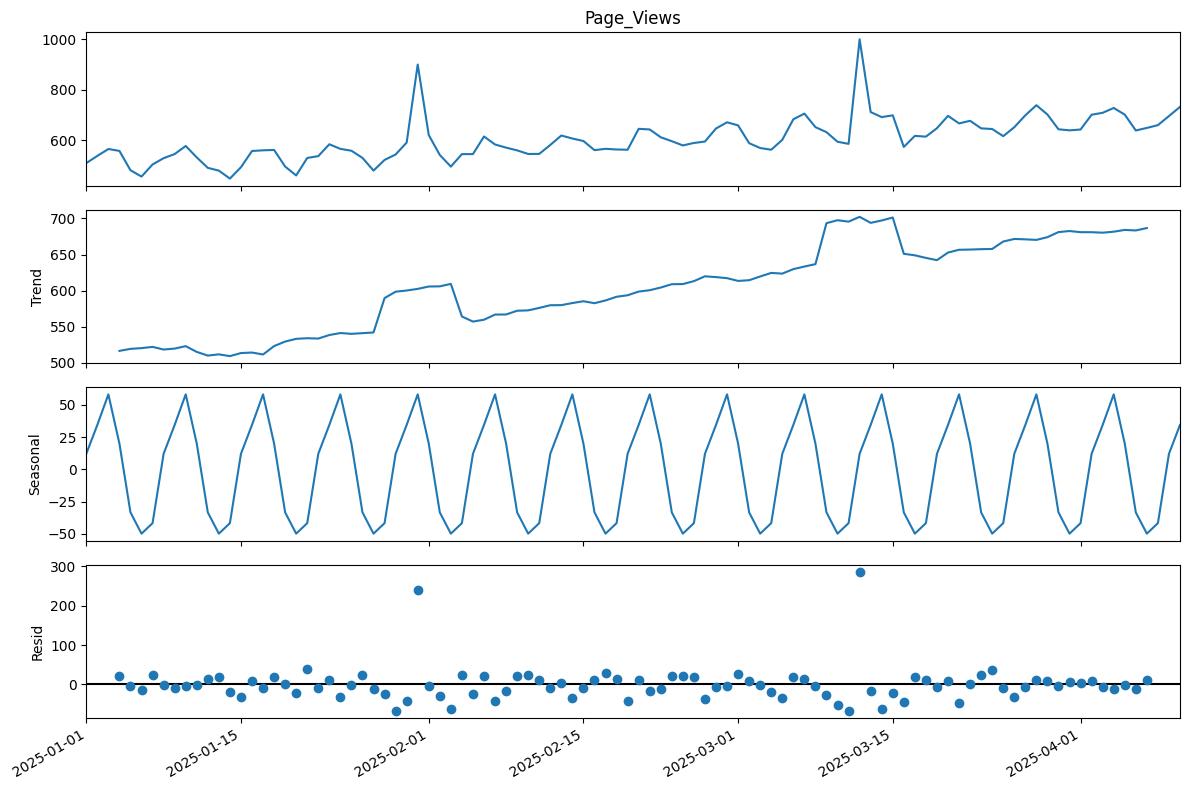

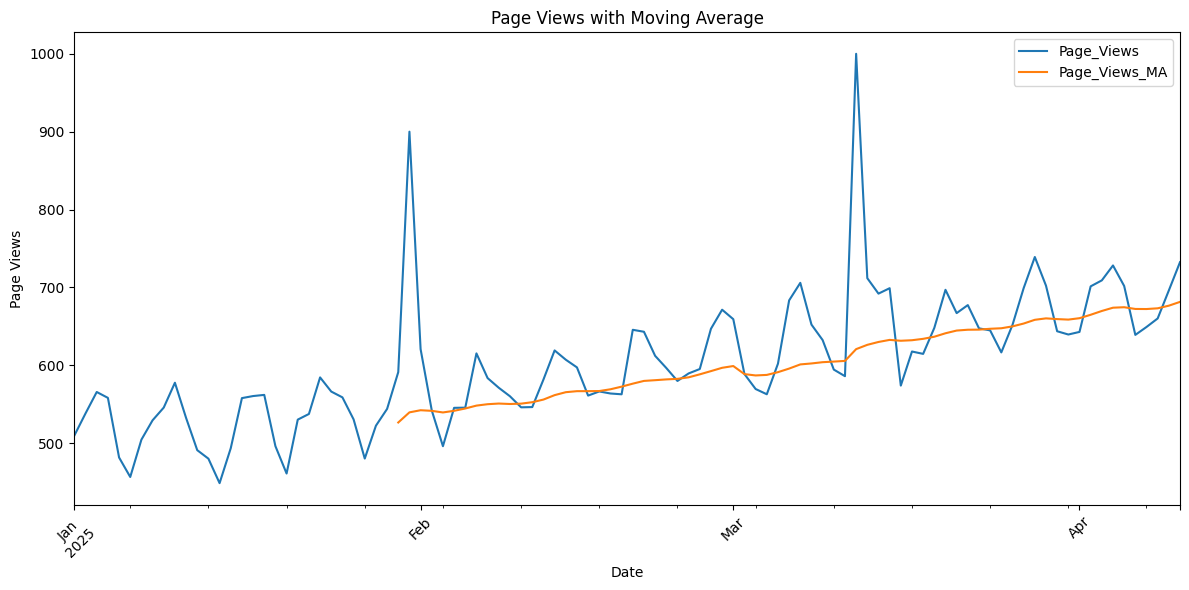


Detected Anomalies:
            Page_Views  Page_Views_Z
Date                                
2025-01-31       900.0      3.470752
2025-03-12      1000.0      4.642807


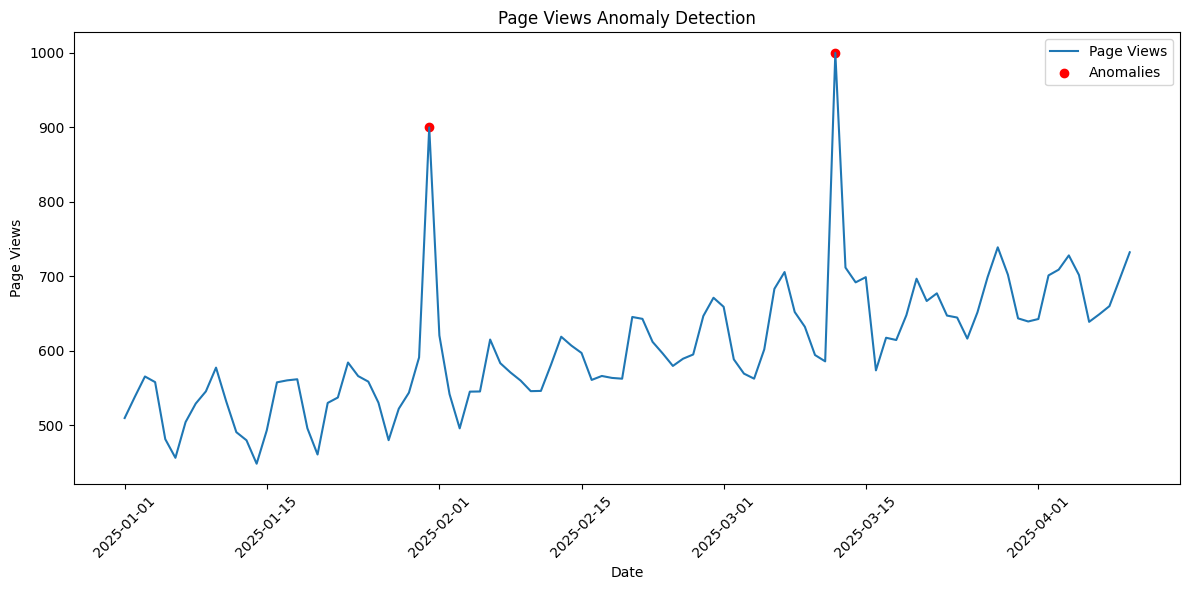

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Create sample website traffic data

np.random.seed(42)

dates = pd.date_range(start="2025-01-01", periods=100, freq="D")

page_views = (
500
+ np.arange(100) * 2
+ 50 * np.sin(2 * np.pi * np.arange(100) / 7)
+ np.random.normal(0, 20, 100)
)

# Add a few artificial anomalies

page_views[30] = 900
page_views[70] = 1000

# Create DataFrame

data = pd.DataFrame({
"Page_Views": page_views
}, index=dates)

data.index.name = "Date"

# Display first five rows

print("First Five Rows:")
print(data.head())

# Seasonal Decomposition

decomposition = seasonal_decompose(
data["Page_Views"],
model="additive",
period=7
)

fig = decomposition.plot()
fig.set_size_inches(12, 8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# Calculate 30-day moving average

data["Page_Views_MA"] = data["Page_Views"].rolling(
window=30
).mean()

# Plot Page Views with Moving Average

data[["Page_Views", "Page_Views_MA"]].plot(
figsize=(12, 6)
)

plt.title("Page Views with Moving Average")
plt.xlabel("Date")
plt.ylabel("Page Views")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Calculate Z-score for anomaly detection

data["Page_Views_Z"] = (
(data["Page_Views"] - data["Page_Views"].mean())
/ data["Page_Views"].std()
)


anomalies = data[data["Page_Views_Z"].abs() > 3]

print("\nDetected Anomalies:")
print(anomalies[["Page_Views", "Page_Views_Z"]])

plt.figure(figsize=(12, 6))

plt.plot(
data.index,
data["Page_Views"],
label="Page Views"
)

plt.scatter(
anomalies.index,
anomalies["Page_Views"],
color="red",
label="Anomalies"
)

plt.xlabel("Date")
plt.ylabel("Page Views")
plt.title("Page Views Anomaly Detection")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()